In [12]:
import torch
from utils import load_fwd

s, d, _, _ = load_fwd('single-bf16.pt', 'bf16')
_, buggy, _, _ = load_fwd('single-bf16.pt', 'bf16-bug')

In [13]:
single = s['batch_0.layer_1.attn'].view(-1).to(torch.float32)
distri = d['batch_0.layer_1.attn'].view(-1).to(torch.float32)
bug = buggy['batch_0.layer_1.attn'].view(-1).to(torch.float32)

In [14]:
mask = torch.abs(single) > 1.2e-38
ss = single[mask]
dd = distri[mask]
bb = bug[mask]

In [15]:
rel = torch.abs(ss - dd) / torch.abs(ss)
a = rel.sort()[0]
brel = torch.abs(ss - bb) / torch.abs(ss)
b = brel.sort()[0]

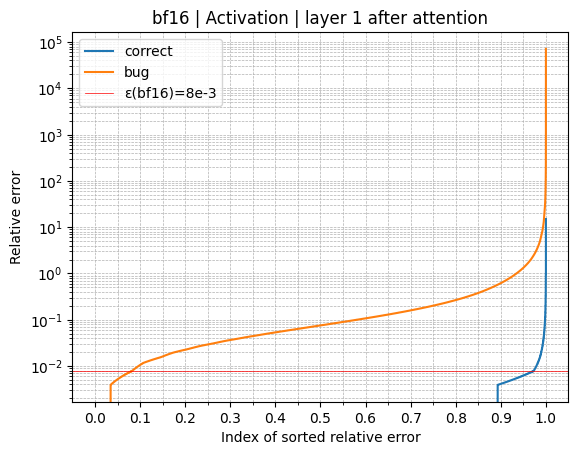

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.plot(np.arange(len(a))/len(a), a.numpy())
plt.plot(np.arange(len(b))/len(b), b.numpy())
plt.axhline(y=8e-3, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.yscale('log')
plt.legend(['correct', 'bug', 'ε(bf16)=8e-3'])
plt.xlabel('Index of sorted relative error')
plt.ylabel('Relative error')
plt.title('bf16 | Activation | layer 1 after attention')
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(0.1))  # 每 1 个单位一个主刻度
plt.gca().xaxis.set_minor_locator(ticker.MultipleLocator(0.05))  # 每 0.2 个单位一个次刻度
plt.gca().yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
plt.gca().yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10))
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

In [18]:
(torch.searchsorted(a, 8e-3) / a.size(0)).item()*100, (torch.searchsorted(b, 8e-3) / b.size(0)).item()*100

(97.3272979259491, 8.301568031311035)